Enter your Roll Number: 51

Roll Number: 51
Grid Size: 99 x 198

EXERCISE 1: ZERO PERTURBATION
-----------------------------------------------------------------
Perturbation Amplitude: 0
Initial Mass: 1.0
Final Mass: 0.9999999999999996
Maximum Speed: 9.726811370236454e-15
Maximum Divergence: 2.5630577949168246e-12


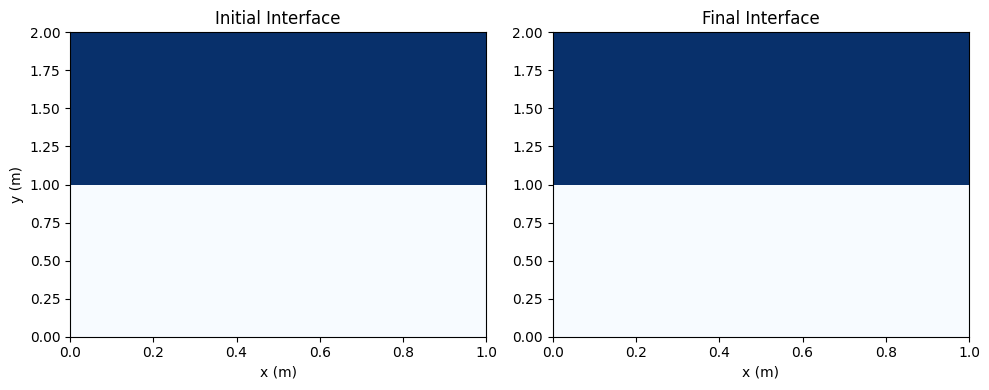


EXERCISE 2: GRID REFINEMENT
-----------------------------------------------------------------
Grid=24x48 | Steps=700 | Thickness=0.750000 m | Mass Error=3.331e-16
Grid=48x96 | Steps=700 | Thickness=0.588542 m | Mass Error=4.441e-16
Grid=96x192 | Steps=861 | Thickness=0.438368 m | Mass Error=1.665e-15


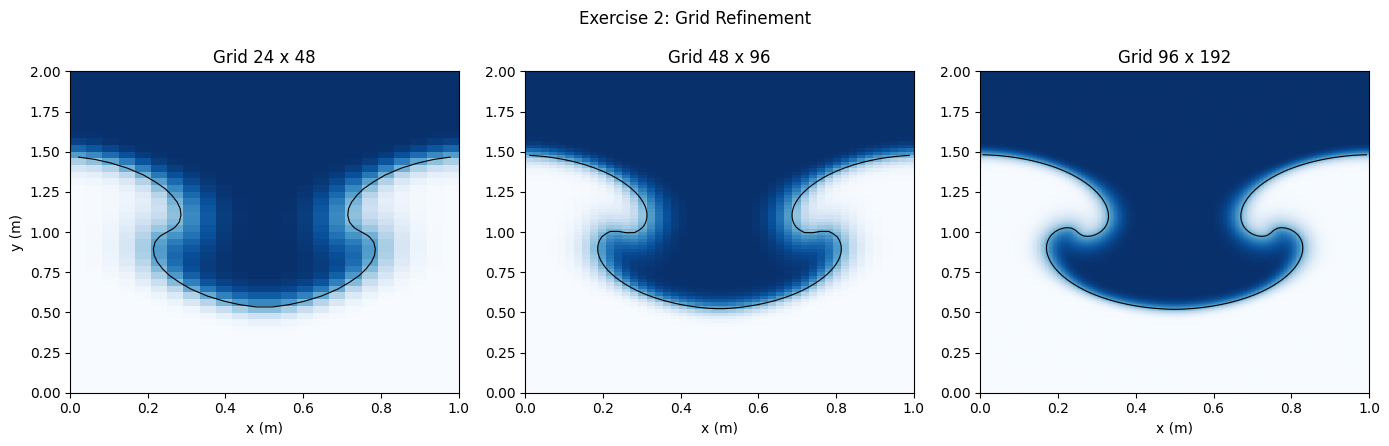


EXERCISE 3: DENSITY CONTRAST
-----------------------------------------------------------------
Heavy Density=1.05 | Atwood Number=0.02439 | Max Speed=0.047789
Heavy Density=1.20 | Atwood Number=0.09091 | Max Speed=0.245761
Heavy Density=1.50 | Atwood Number=0.20000 | Max Speed=0.678173
Heavy Density=2.00 | Atwood Number=0.33333 | Max Speed=1.448448


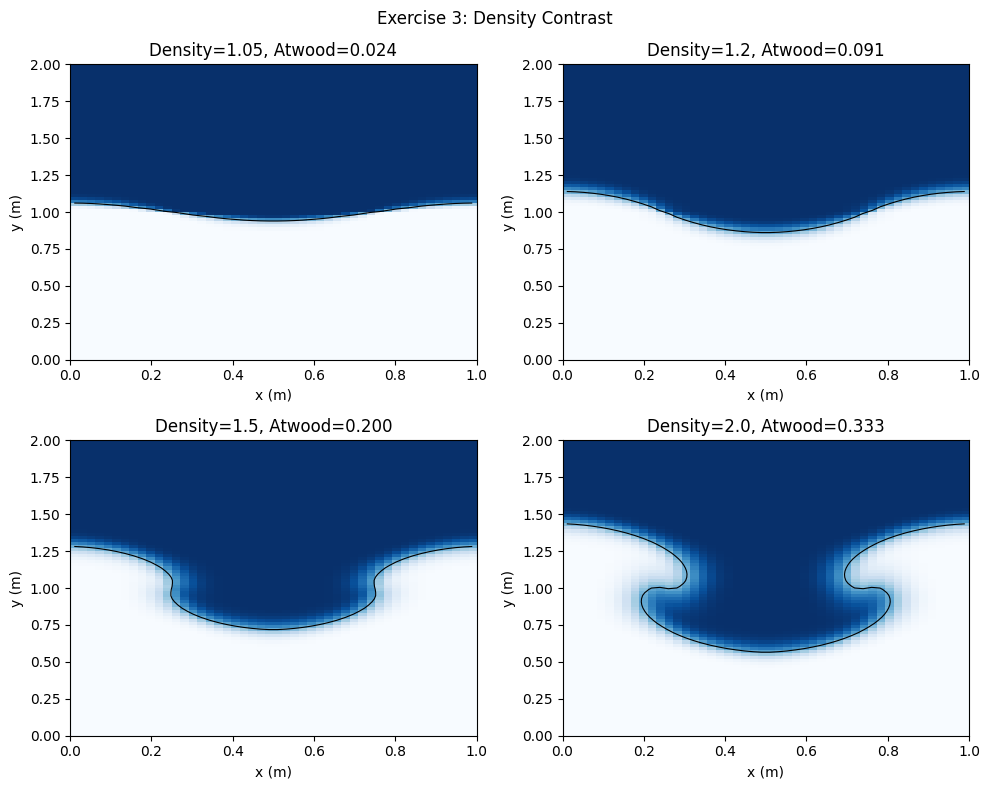


EXERCISE 4: PHASE CONSERVATION
-----------------------------------------------------------------
Initial Heavy Fluid Area: 1.0
Final Heavy Fluid Area: 0.9999999999999996
Relative Mass Error: 4.440892098500626e-16


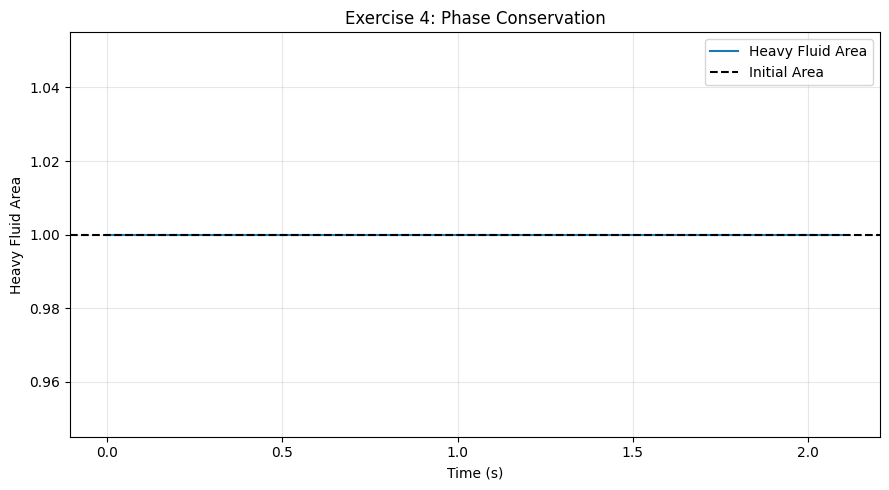


MAIN EXPERIMENT RESULTS
-----------------------------------------------------------------
Roll Number: 51
Grid: 99 x 198
dx: 0.010101
dy: 0.010101
Time Steps: 915
Initial Area: 1.000000000000
Final Area: 1.000000000000
Relative Mass Error: 5.551e-16
Volume Fraction Min: 0.000000
Volume Fraction Max: 1.000000
Maximum Divergence: 1.332e-11
Maximum Speed: 0.876987
Interface Thickness: 0.433425 m


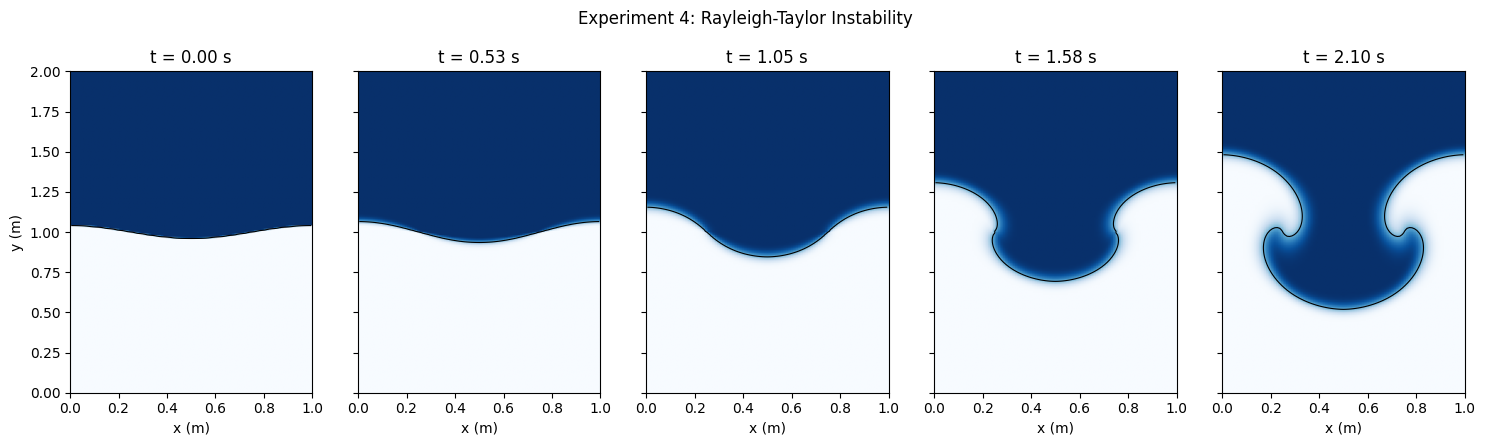


ALL SIMULATIONS COMPLETED.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import factorized

# ============================================
# STUDENT INPUT
# ============================================

roll_no = 20  # Roll number

nx_roll = 48 + roll_no
ny_roll = 2 * nx_roll

print("\nRoll Number:", roll_no)
print(f"Grid Size: {nx_roll} x {ny_roll}")

# ============================================
# COMMON PARAMETERS
# ============================================

Lx, Ly = 1.0, 2.0
rho_light = 1.0
rho_heavy = 1.2
g = 9.81
nu = 0.005
t_end = 2.1

amplitude = 0.04


# ============================================
# SIMULATION FUNCTION
# ============================================

def run_simulation(nx, ny, amp=0.04,
                   rho_h=1.2, final_time=2.1):

    dx = Lx / nx
    dy = Ly / ny

    rho_ref = 0.5 * (rho_light + rho_h)

    x = (np.arange(nx) + 0.5) * dx
    y = (np.arange(ny) + 0.5) * dy

    interface = (
        Ly / 2 + amp * np.cos(2 * np.pi * x / Lx)
    )

    alpha = np.clip(
        (y[:, None] + dy / 2 - interface[None, :]) / dy,
        0, 1
    )

    u = np.zeros((ny, nx))
    v = np.zeros((ny + 1, nx))

    # Pressure matrix

    Lx_op = diags(
        [np.ones(nx-1), -2*np.ones(nx),
         np.ones(nx-1)],
        [-1, 0, 1]
    ).tolil()

    Lx_op[0, -1] = 1
    Lx_op[-1, 0] = 1

    Ly_op = diags(
        [np.ones(ny-1), -2*np.ones(ny),
         np.ones(ny-1)],
        [-1, 0, 1]
    ).tolil()

    Ly_op[0, 0] = -1
    Ly_op[-1, -1] = -1

    lap = (
        kron(eye(ny), Lx_op / dx**2)
        + kron(Ly_op / dy**2, eye(nx))
    ).tolil()

    lap[0, :] = 0
    lap[0, 0] = 1

    solve_pressure = factorized(lap.tocsc())

    # Initial values

    initial_mass = alpha.sum() * dx * dy

    mass_history = [initial_mass]
    time_history = [0.0]

    snapshots = [(0.0, alpha.copy())]

    t = 0.0
    steps = 0
    maximum_divergence = 0.0

    snapshot_times = np.linspace(0, final_time, 5)
    next_snapshot = 1

    # ========================================
    # TIME LOOP
    # ========================================

    while t < final_time - 1e-12:

        adv_rate = (
            np.max(np.abs(u)) / dx
            + np.max(np.abs(v)) / dy
        )

        dt = min(
            0.003,
            0.3 / max(adv_rate, 1e-12),
            0.45 / (
                2 * nu * (1/dx**2 + 1/dy**2)
            ),
            final_time - t
        )

        # VOF advection

        fx = u * np.where(
            u >= 0,
            np.roll(alpha, 1, axis=1),
            alpha
        )

        lower = np.vstack((alpha[:1], alpha))
        upper = np.vstack((alpha, alpha[-1:]))

        fy = v * np.where(v >= 0, lower, upper)

        alpha = alpha - dt * (
            (np.roll(fx, -1, axis=1) - fx) / dx
            + (fy[1:] - fy[:-1]) / dy
        )

        # Horizontal momentum

        ue = 0.5 * (u + np.roll(u, -1, axis=1))
        uw = 0.5 * (u + np.roll(u, 1, axis=1))

        un = np.roll(u, -1, axis=0)
        us = np.roll(u, 1, axis=0)

        vn = 0.5 * (
            v[1:] + np.roll(v[1:], 1, axis=1)
        )

        vs = 0.5 * (
            v[:-1] + np.roll(v[:-1], 1, axis=1)
        )

        un[-1] = u[-1]
        us[0] = u[0]

        flux_ue = ue * np.where(
            ue >= 0, u, np.roll(u, -1, axis=1)
        )

        flux_uw = uw * np.where(
            uw >= 0, np.roll(u, 1, axis=1), u
        )

        flux_un = vn * np.where(vn >= 0, u, un)
        flux_us = vs * np.where(vs >= 0, us, u)

        conv_u = (
            (flux_ue - flux_uw) / dx
            + (flux_un - flux_us) / dy
        )

        lap_u = (
            (np.roll(u, -1, axis=1) - 2*u
             + np.roll(u, 1, axis=1)) / dx**2
        )

        lap_u += (un - 2*u + us) / dy**2

        u_star = u + dt * (-conv_u + nu * lap_u)

        # Vertical momentum

        vm = v[1:-1]

        ve = 0.5 * (
            np.roll(u[:-1], -1, axis=1)
            + np.roll(u[1:], -1, axis=1)
        )

        vw = 0.5 * (u[:-1] + u[1:])

        vne = 0.5 * (vm + v[2:])
        vsw = 0.5 * (vm + v[:-2])

        flux_ve = ve * np.where(
            ve >= 0, vm, np.roll(vm, -1, axis=1)
        )

        flux_vw = vw * np.where(
            vw >= 0, np.roll(vm, 1, axis=1), vm
        )

        flux_vn = vne * np.where(
            vne >= 0, vm, v[2:]
        )

        flux_vs = vsw * np.where(
            vsw >= 0, v[:-2], vm
        )

        conv_v = (
            (flux_ve - flux_vw) / dx
            + (flux_vn - flux_vs) / dy
        )

        lap_v = (
            (np.roll(vm, -1, axis=1) - 2*vm
             + np.roll(vm, 1, axis=1)) / dx**2
        )

        lap_v += (v[2:] - 2*vm + v[:-2]) / dy**2

        buoyancy = (
            -g * (rho_h - rho_light)
            * (alpha[:-1] + alpha[1:] - 1)
            / (2 * rho_ref)
        )

        v_star = v.copy()

        v_star[1:-1] = vm + dt * (
            -conv_v + nu * lap_v + buoyancy
        )

        # Pressure correction

        divergence = (
            (np.roll(u_star, -1, axis=1) - u_star) / dx
        )

        divergence += (
            v_star[1:] - v_star[:-1]
        ) / dy

        rhs = (rho_ref / dt * divergence).ravel()
        rhs[0] = 0

        p = solve_pressure(rhs).reshape(ny, nx)

        u = u_star - (
            dt / (rho_ref * dx)
        ) * (p - np.roll(p, 1, axis=1))

        v = v_star.copy()

        v[1:-1] -= (
            dt / (rho_ref * dy)
        ) * (p[1:] - p[:-1])

        # Divergence

        current_div = (
            (np.roll(u, -1, axis=1) - u) / dx
        )

        current_div += (
            v[1:] - v[:-1]
        ) / dy

        maximum_divergence = max(
            maximum_divergence,
            np.max(np.abs(current_div))
        )

        if alpha.min() < -1e-8 or alpha.max() > 1+1e-8:
            raise RuntimeError("Volume fraction out of bounds")

        # Update time

        t += dt
        steps += 1

        current_mass = alpha.sum() * dx * dy

        mass_history.append(current_mass)
        time_history.append(t)

        if (
            next_snapshot < len(snapshot_times)
            and t >= snapshot_times[next_snapshot] - 1e-12
        ):
            snapshots.append((t, alpha.copy()))
            next_snapshot += 1

    if len(snapshots) < len(snapshot_times):
        snapshots.append((t, alpha.copy()))

    final_mass = alpha.sum() * dx * dy

    # Numerical interface thickness

    mixed_cells = (alpha > 0.01) & (alpha < 0.99)

    thickness_per_column = (
        np.sum(mixed_cells, axis=0) * dy
    )

    interface_thickness = np.mean(thickness_per_column)

    max_speed = max(
        np.max(np.abs(u)),
        np.max(np.abs(v))
    )

    return {
        "alpha": alpha,
        "initial": snapshots[0][1],
        "snapshots": snapshots,
        "x": x,
        "y": y,
        "steps": steps,
        "mass": final_mass,
        "initial_mass": initial_mass,
        "mass_history": mass_history,
        "time_history": time_history,
        "divergence": maximum_divergence,
        "max_speed": max_speed,
        "thickness": interface_thickness,
        "relative_error": abs(
            final_mass - initial_mass
        ) / max(abs(initial_mass), 1e-15),
        "dx": dx,
        "dy": dy
    }


# ============================================
# EXERCISE 1: ZERO PERTURBATION AMPLITUDE
# ============================================

print("\nEXERCISE 1: ZERO PERTURBATION")
print("-" * 65)

zero = run_simulation(
    48, 96,
    amp=0.0,
    final_time=0.5
)

print("Perturbation Amplitude: 0")
print("Initial Mass:", zero["initial_mass"])
print("Final Mass:", zero["mass"])
print("Maximum Speed:", zero["max_speed"])
print("Maximum Divergence:", zero["divergence"])

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].imshow(
    zero["initial"],
    origin="lower",
    extent=(0, Lx, 0, Ly),
    cmap="Blues",
    vmin=0, vmax=1,
    aspect="auto"
)

axs[0].set_title("Initial Interface")
axs[0].set_xlabel("x (m)")
axs[0].set_ylabel("y (m)")

axs[1].imshow(
    zero["alpha"],
    origin="lower",
    extent=(0, Lx, 0, Ly),
    cmap="Blues",
    vmin=0, vmax=1,
    aspect="auto"
)

axs[1].set_title("Final Interface")
axs[1].set_xlabel("x (m)")

plt.tight_layout()
plt.savefig("exercise_1_zero_amplitude.png", dpi=180)
plt.show()


# ============================================
# EXERCISE 2: GRID COMPARISON
# ============================================

print("\nEXERCISE 2: GRID REFINEMENT")
print("-" * 65)

grids = [(24, 48), (48, 96), (96, 192)]

grid_results = []

fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))

for ax, (nx, ny) in zip(axs, grids):

    res = run_simulation(nx, ny)

    grid_results.append(res)

    print(
        f"Grid={nx}x{ny} | "
        f"Steps={res['steps']} | "
        f"Thickness={res['thickness']:.6f} m | "
        f"Mass Error={res['relative_error']:.3e}"
    )

    ax.imshow(
        res["alpha"],
        origin="lower",
        extent=(0, Lx, 0, Ly),
        cmap="Blues",
        vmin=0, vmax=1,
        aspect="auto"
    )

    ax.contour(
        res["x"], res["y"],
        res["alpha"],
        levels=[0.5],
        colors="black",
        linewidths=0.8
    )

    ax.set_title(f"Grid {nx} x {ny}")
    ax.set_xlabel("x (m)")

axs[0].set_ylabel("y (m)")

fig.suptitle("Exercise 2: Grid Refinement")
plt.tight_layout()
plt.savefig("exercise_2_grid_comparison.png", dpi=180)
plt.show()


# ============================================
# EXERCISE 3: DENSITY CONTRAST
# ============================================

print("\nEXERCISE 3: DENSITY CONTRAST")
print("-" * 65)

density_values = [1.05, 1.2, 1.5, 2.0]

density_results = []

for rho_h in density_values:

    atwood = (
        (rho_h - rho_light)
        / (rho_h + rho_light)
    )

    res = run_simulation(
        48, 96,
        amp=0.04,
        rho_h=rho_h,
        final_time=1.0
    )

    density_results.append((rho_h, atwood, res))

    print(
        f"Heavy Density={rho_h:.2f} | "
        f"Atwood Number={atwood:.5f} | "
        f"Max Speed={res['max_speed']:.6f}"
    )

fig, axs = plt.subplots(2, 2, figsize=(10, 8))

for ax, (rho_h, atwood, res) in zip(
    axs.flat, density_results
):

    ax.imshow(
        res["alpha"],
        origin="lower",
        extent=(0, Lx, 0, Ly),
        cmap="Blues",
        vmin=0, vmax=1,
        aspect="auto"
    )

    ax.contour(
        res["x"], res["y"],
        res["alpha"],
        levels=[0.5],
        colors="black",
        linewidths=0.8
    )

    ax.set_title(
        f"Density={rho_h}, Atwood={atwood:.3f}"
    )

    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

fig.suptitle("Exercise 3: Density Contrast")
plt.tight_layout()
plt.savefig("exercise_3_density_contrast.png", dpi=180)
plt.show()


# ============================================
# EXERCISE 4: PHASE CONSERVATION
# ============================================

print("\nEXERCISE 4: PHASE CONSERVATION")
print("-" * 65)

phase = run_simulation(
    48, 96,
    amp=0.04,
    final_time=2.1
)

print("Initial Heavy Fluid Area:", phase["initial_mass"])
print("Final Heavy Fluid Area:", phase["mass"])
print("Relative Mass Error:", phase["relative_error"])

plt.figure(figsize=(9, 5))

plt.plot(
    phase["time_history"],
    phase["mass_history"],
    label="Heavy Fluid Area"
)

plt.axhline(
    phase["initial_mass"],
    linestyle="--",
    color="black",
    label="Initial Area"
)

plt.xlabel("Time (s)")
plt.ylabel("Heavy Fluid Area")
plt.title("Exercise 4: Phase Conservation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("exercise_4_phase_conservation.png", dpi=180)
plt.show()


# ============================================
# MAIN EXPERIMENT
# ============================================

print("\nMAIN EXPERIMENT RESULTS")
print("-" * 65)

main = run_simulation(
    nx_roll,
    ny_roll,
    amp=0.04,
    final_time=2.1
)

print(f"Roll Number: {roll_no}")
print(f"Grid: {nx_roll} x {ny_roll}")
print(f"dx: {main['dx']:.6f}")
print(f"dy: {main['dy']:.6f}")
print(f"Time Steps: {main['steps']}")
print(f"Initial Area: {main['initial_mass']:.12f}")
print(f"Final Area: {main['mass']:.12f}")
print(f"Relative Mass Error: {main['relative_error']:.3e}")
print(f"Volume Fraction Min: {main['alpha'].min():.6f}")
print(f"Volume Fraction Max: {main['alpha'].max():.6f}")
print(f"Maximum Divergence: {main['divergence']:.3e}")
print(f"Maximum Speed: {main['max_speed']:.6f}")
print(f"Interface Thickness: {main['thickness']:.6f} m")


# ============================================
# FINAL SNAPSHOT GRAPH
# ============================================

fig, axs = plt.subplots(
    1, len(main["snapshots"]),
    figsize=(15, 4.5),
    sharex=True,
    sharey=True
)

for ax, (ti, ai) in zip(
    axs, main["snapshots"]
):

    ax.imshow(
        ai,
        origin="lower",
        extent=(0, Lx, 0, Ly),
        cmap="Blues",
        vmin=0, vmax=1,
        aspect="auto"
    )

    ax.contour(
        main["x"],
        main["y"],
        ai,
        levels=[0.5],
        colors="black",
        linewidths=0.8
    )

    ax.set_title(f"t = {ti:.2f} s")
    ax.set_xlabel("x (m)")

axs[0].set_ylabel("y (m)")

fig.suptitle("Experiment 4: Rayleigh-Taylor Instability")

plt.tight_layout()
plt.savefig("experiment_4_rti_output.png", dpi=180)
plt.show()


# ============================================
# FINAL COMPLETION
# ============================================

print("\nALL SIMULATIONS COMPLETED.")
